<a href="https://colab.research.google.com/github/igormuskatblit/CBOE-Pitch/blob/main/lf2hf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Low Fidelity to high fidelity Delta Machine learning for signals**



Say KS has 20 Ghz device in our product portfolio. Thats' the one they ship regularly. They also have a high end 3 Thz device for the next gen frequency (data transfer at ultra high frequency next gen). This device is super high end, sensitive, cannot be shipped or produced in large quantities.

**IMPORTANT OBSERVATION 1**

Clients that request next gen 3 Thz devices don't need these for arbitrary signals but those relevant for their specific application. Might differ from sector to sector. ie Ethernet signals @ 100Gbps,200, 400 and 800 -> 1.64Tbps, 3.4Tps and 6.4Tbs

**IMPORTANT OBSERVATION 2**

The 20 Ghz devices alone will not be able to recover the full 3 Thz resolution - there will be information loss.
HOWEVER there is no need to recover the complete signal - we only need the specific signal the customer is interested in. We will be able to recover this much smaller specific part of the spectrum with our Delta ML architecture and ShapeBricks

**Problem**


At its core, this is about **calibrating** a low-resolution measurement device (a low fidelity LF oscilloscope”) so that, once trained, it can **reconstruct** specific signals nearly as faithfully as a high-resolution, high-cost instrument.
Note that we dont care about reconstructing the complete signal of the high end high fidelity device but only the "Shapes" (ShapeBricks) of signals a client is interested in.


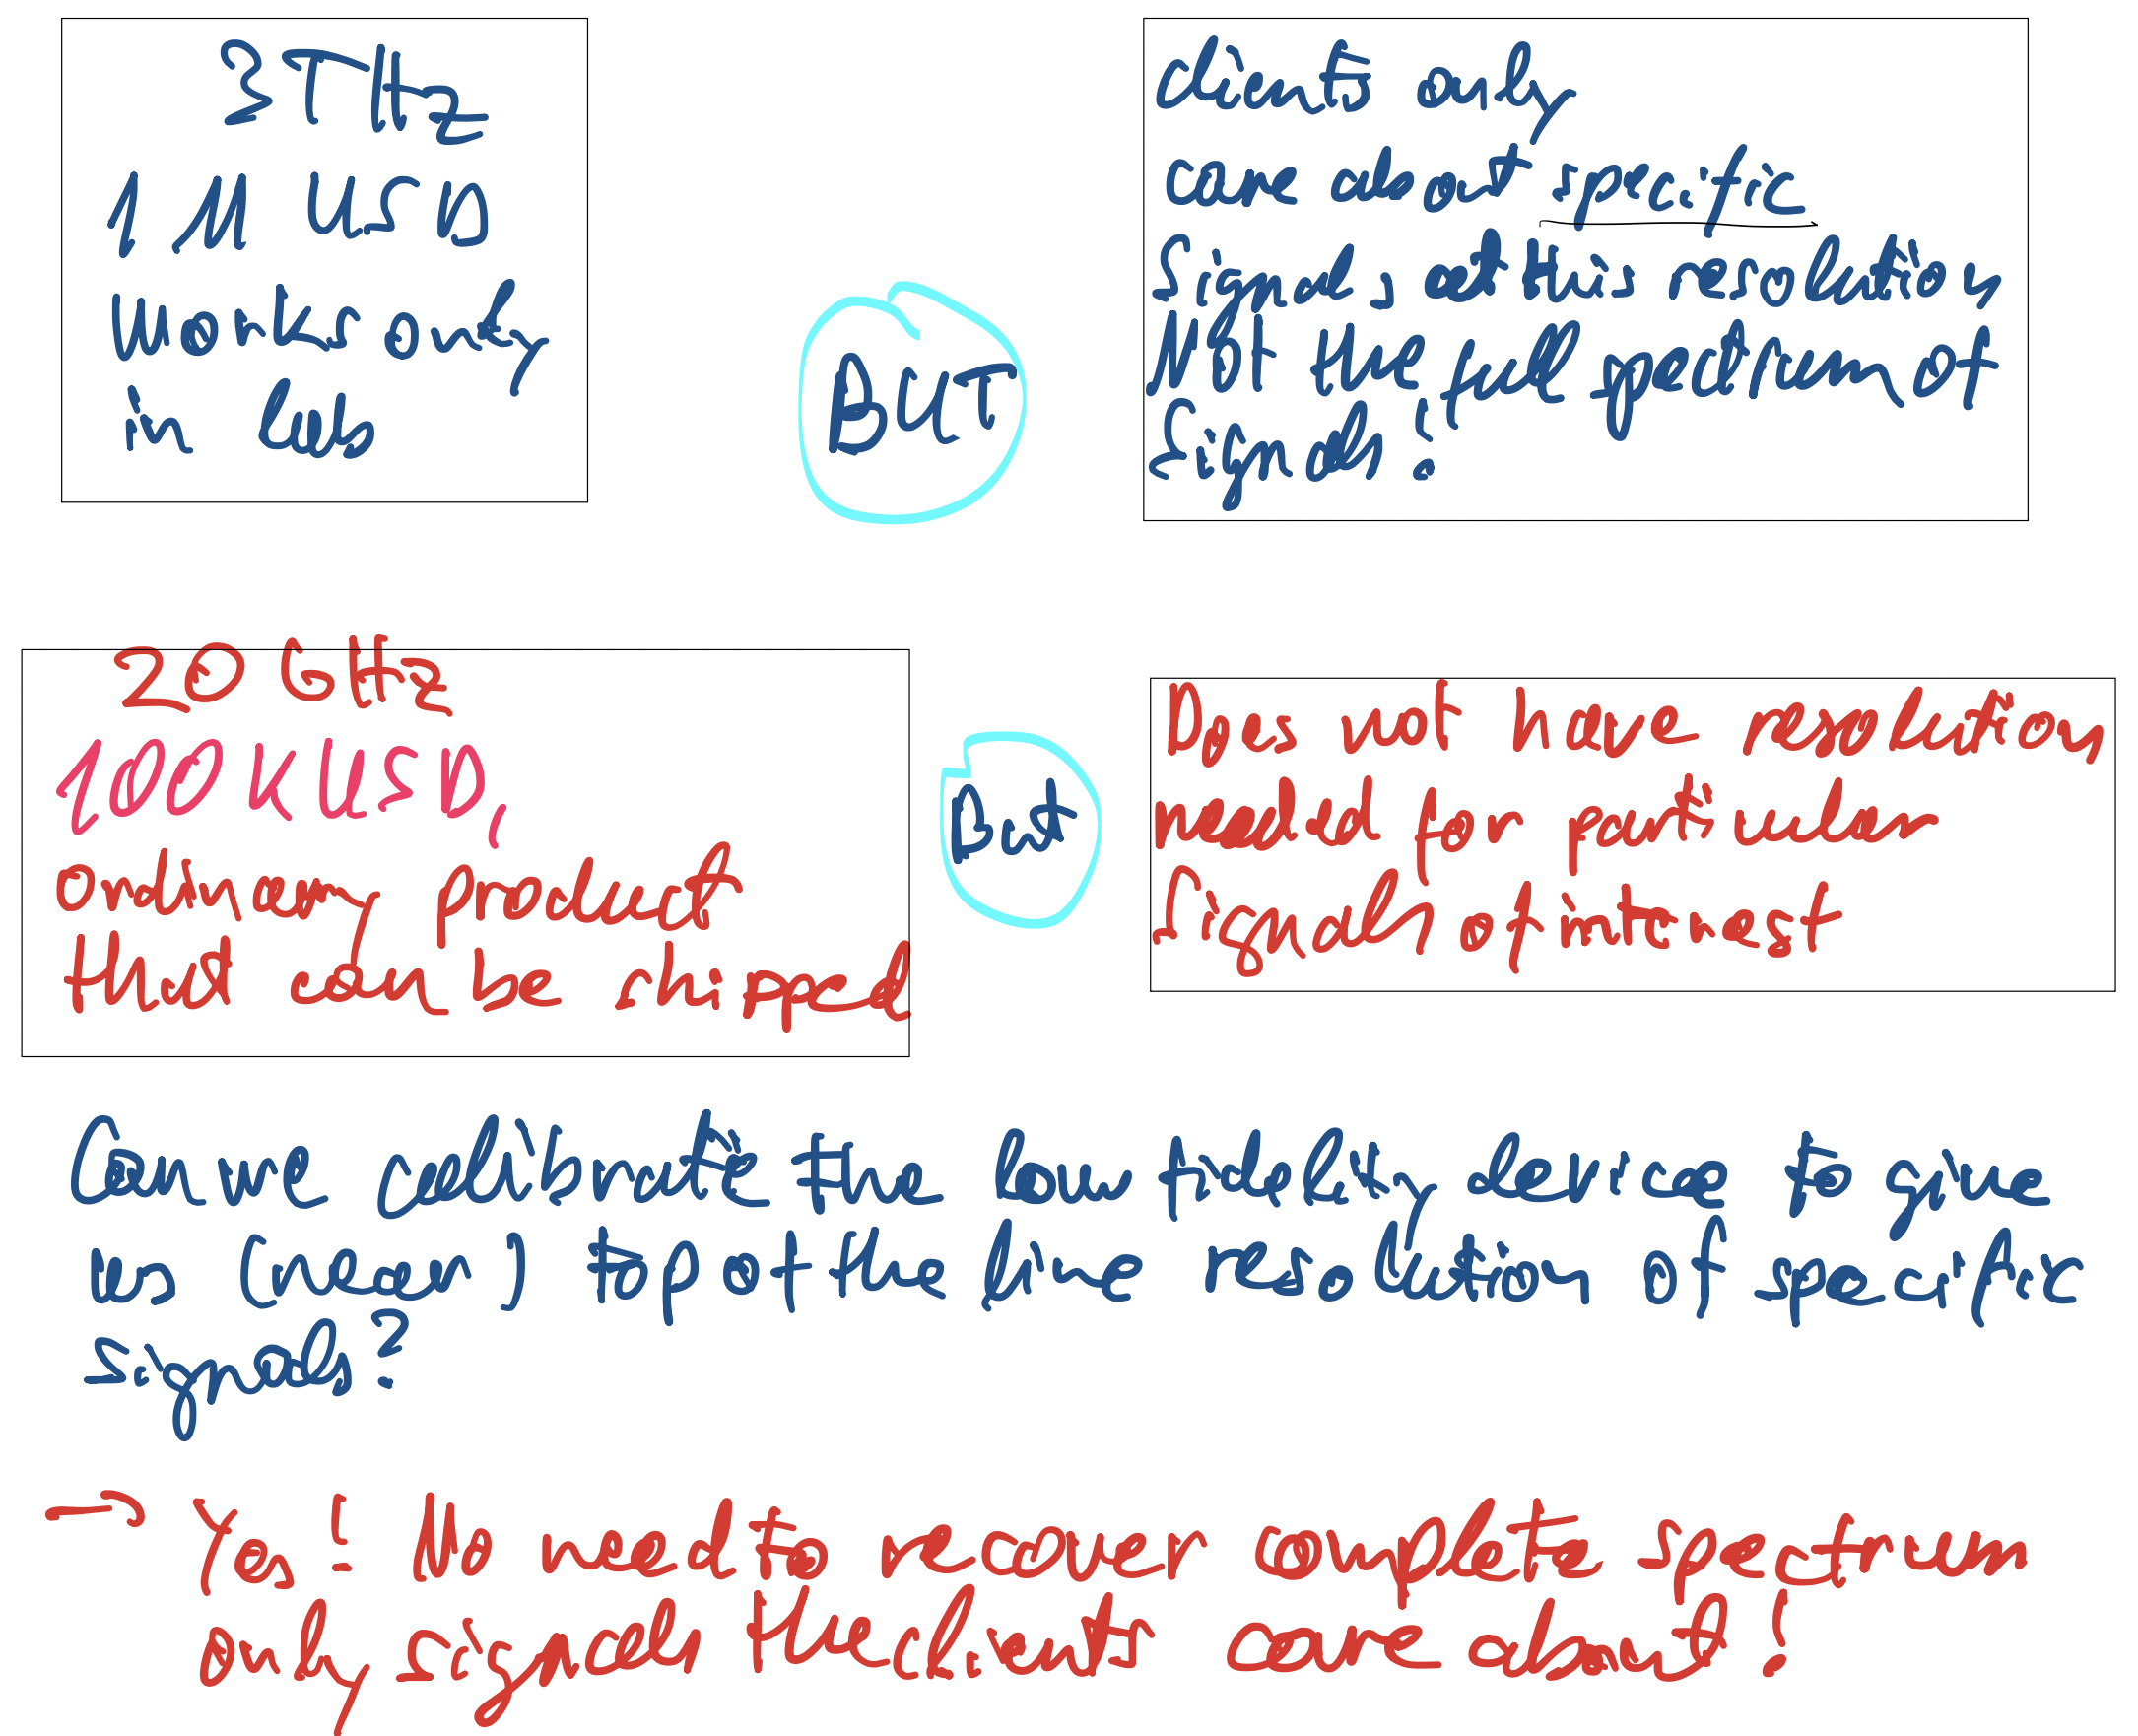



---

### Motivation
- **Problem:** A low-resolution device cannot capture fine details of certain signals.  
- **Goal:** Learn a mapping (“Δ-learning”) that fills in missing high-frequency content, enabling the LF device to mimic the HF device’s performance for SPECIFIC signal shapes. Then SHIP the 20 Ghz low fidelity device with this enhanced capability



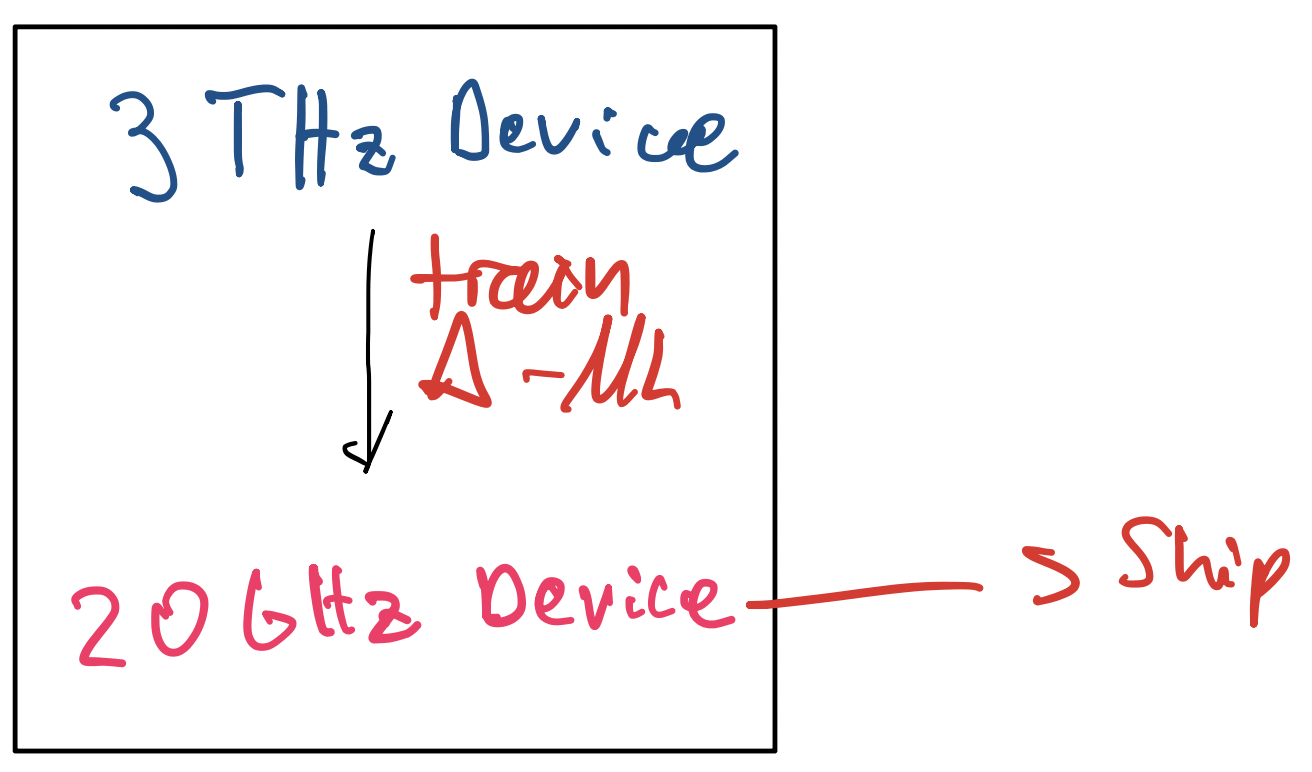



---

### 1. Define the Problem
- **True waveform** (`f_true_complex`): Here we just generate some pseudo signal for the sake of demonstrating the concept.

- **LF measurement** (`f_base_complex`): phase-shifted, amplitude-scaled, noisy version at coarse sampling.  
- **Objective:** Recover the true HF waveform from its LF sampling.

---

### 2. Time-Domain ShapeBrick Dictionary
- Build a shared set of **atomic basis functions** (“ShapeBricks”):
Say customer cares about these types of SignalShapes

  - **Polynomials** (constant, linear, quadratic)  
  - **Gaussian bumps** (localized peaks at multiple centers and widths)  
  - **Raised-cosine windows** (smooth plateaus)  
  - **Haar wavelets** (multi-scale jumps)  
- Evaluate these bricks on both HF (500 points) and LF (100 points) time grids. Why more HF than LF points? Well it is assumed to be higher resolution so its 5 x more datapoints for the same time interval

---

### 3. Coefficient Extraction

For each of **N** synthetic examples:
1. **Sample** the true signal at HF times and the LF signal at LF times. (align measurements)

2. **Project** each onto the ShapeBrick basis with $K$ different bricks via **Ridge regression** → coefficient vectors  

   $\;a_{\rm HF}\in\mathbb R^K $ and $\;a_{\rm LF}\in\mathbb R^K $.

---

### 4. Δ-Learning
- Compute difference between the coefficients (weight-factors) of the bricks.
This is to create the labels for Delta Machine learning.
We call this **delta coefficients**  

$$\delta = a_{\rm HF} \;-\; a_{\rm LF}$$
  

- **Standardize** the LF coefficients.  
- **Train** a model to predict the difference of the ShapeBrick coefficient to the high fidelity signal, given the low fidelity signal:

$$a_{\rm LF} \;\longrightarrow\; \delta$$


---

### 5. Inference & Reconstruction
Given a new LF measurement:




1. **Extract** $a_{\rm LF}$ on the ShapeBrick basis.  
2. **Predict** $\hat\delta$ using the trained model.  
3. **Form** $\hat a_{\rm HF} = a_{\rm LF} + \hat\delta\$.  
4. **Synthesize** the HF waveform on the fine grid.

$$\hat y_{\rm HF}(t)
     = \sum_{k=1}^K \hat a_{\rm HF,k} \phi_k(t)$$


  

---

### 6. Visualization & Deployment
- **ShapeBrick Plot:** Inspect the library of basis functions.  
- **Metrics Reported:**  
  - **Delta MAE:** accuracy of coefficient corrections.  
  - **Signal MAE:** closeness of reconstructed waveform to true HF.  
- **Final Plot:** LF input points, true HF curve, and reconstructed HF curve overlaid.  
- **Save Pipeline:** Persist the trained model + scaler for real-device calibration.

---

**Key Insight:**  
By performing Δ-learning in a compact ShapeBrick coefficient space—rather than directly on raw waveforms—we efficiently recover high-resolution detail from low-resolution measurements, transforming an inexpensive LF device into a proxy for a high-end oscilloscope.  

**Next we go over the code to achieve this step by step.**


**The code imports essential libraries for this project:**

numpy: For numerical operations and handling data arrays.

sklearn: For machine learning tasks (Random Forest for the model, Ridge for coefficient solving, StandardScaler for data scaling, train_test_split for splitting data, and mean_absolute_error for evaluating the model).

matplotlib.pyplot: For creating plots and visualizations.

joblib: For saving and loading the trained model.
These libraries provide the fundamental tools needed for the calibration pipeline.

In [ ]:
#!/usr/bin/env python3
"""
Calibration pipeline: low-fidelity to high-fidelity Δ-learning
– including ShapeBrick visualization of the atomic basis
"""


import numpy as np
from sklearn.ensemble        import RandomForestRegressor
from sklearn.linear_model   import Ridge
from sklearn.preprocessing  import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics        import mean_absolute_error
import matplotlib.pyplot     as plt
import joblib

We define a more complex “true” signal and a distorted baseline. The "true" signal corresponds to whatever is recorded by the high fidelity device. The "base" signal corresponds to the same signal but recorded with the low fidelity device.

In [ ]:
# 1. Define a more complex “true” signal and a distorted baseline
def f_true_complex(t):
    return (1.0*np.sin(2*np.pi*t)
            + 0.5*np.sin(6*np.pi*t)
            + 0.2*t
            + 0.7*np.exp(-((t-0.3)/0.05)**2))

def f_base_complex(t):
    return (0.8*np.sin(2*np.pi*t + 0.2)
            + 0.4*np.sin(6*np.pi*t + 0.5)
            + 0.1*t
            + 0.5*np.exp(-((t-0.35)/0.07)**2)
            + 0.05*np.random.randn(len(t)))

We define a function to give us the low fidelity and high fidelity signals based

In [ ]:
# 2. Synthetic pair generator
def generate_pair(t_hf, t_lf):
    y_true = f_true_complex(t_hf)
    y_base = f_base_complex(t_lf)
    return y_true, y_base

Define our ShapeBricks functions - could be any other set of functions this is just for illustration.

In [ ]:
# 3. Atom dictionary definitions
def build_dictionary(t):
    # Polynomial ShapeBricks
    P = np.vstack([np.ones_like(t), t, t**2]).T
    # Gaussian ShapeBricks
    centers = np.linspace(0, 1, 10)
    sigmas  = [0.03, 0.07, 0.1]
    G = np.column_stack([np.exp(-0.5*((t-mu)/s)**2)
                         for mu in centers for s in sigmas])
    # Raised-Cosine ShapeBricks
    width = 0.1
    C = np.column_stack([np.where(np.abs(t-mu)<=width,
                                   0.5*(1+np.cos(np.pi*(t-mu)/width)),
                                   0)
                         for mu in centers])
    # Haar-Wavelet ShapeBricks
    def psi(u):
        return np.where((u>=0)&(u<0.5), 1,
                        np.where((u>=0.5)&(u<1), -1, 0))
    H = np.column_stack([2**(j/2)*psi(2**j*t - k)
                         for j in (1,2,3) for k in range(2**j)])
    return P, G, C, H


Given a sampled signal vector  
  $y \;\in\;\mathbb R^{N}, $
we seek coefficient vector  

  $a\;\in\;\mathbb R^K$
that minimizes the **regularized** squared error:
$$
  \min_{a}\;\|\Phi\,a - y\|_2^2 \;+\;\alpha\,\|a\|_2^2.
$$
Here $\alpha>0$ controls the amount of L₂-shrinkage to stabilize the fit when basis functions are correlated or $K$ is large.



This is equivalent to solving:
$
  \bigl(\Phi^\top \Phi \;+\;\alpha\,I\bigr)\,a \;=\;\Phi^\top\,y.
$
Ridge regression efficiently computes the solution and returns a single coefficient vector which is what we do in the following cell.

In [ ]:
# 4. Coefficient solver with Ridge regularization
def solve_coeffs(Phi, y, alpha=1e-2):
    ridge = Ridge(alpha=alpha, fit_intercept=False)
    ridge.fit(Phi, y)
    return ridge.coef_

Now we really get started;
Define the time interval from 0 to 1,
initialize the ShapeBricks and plot them

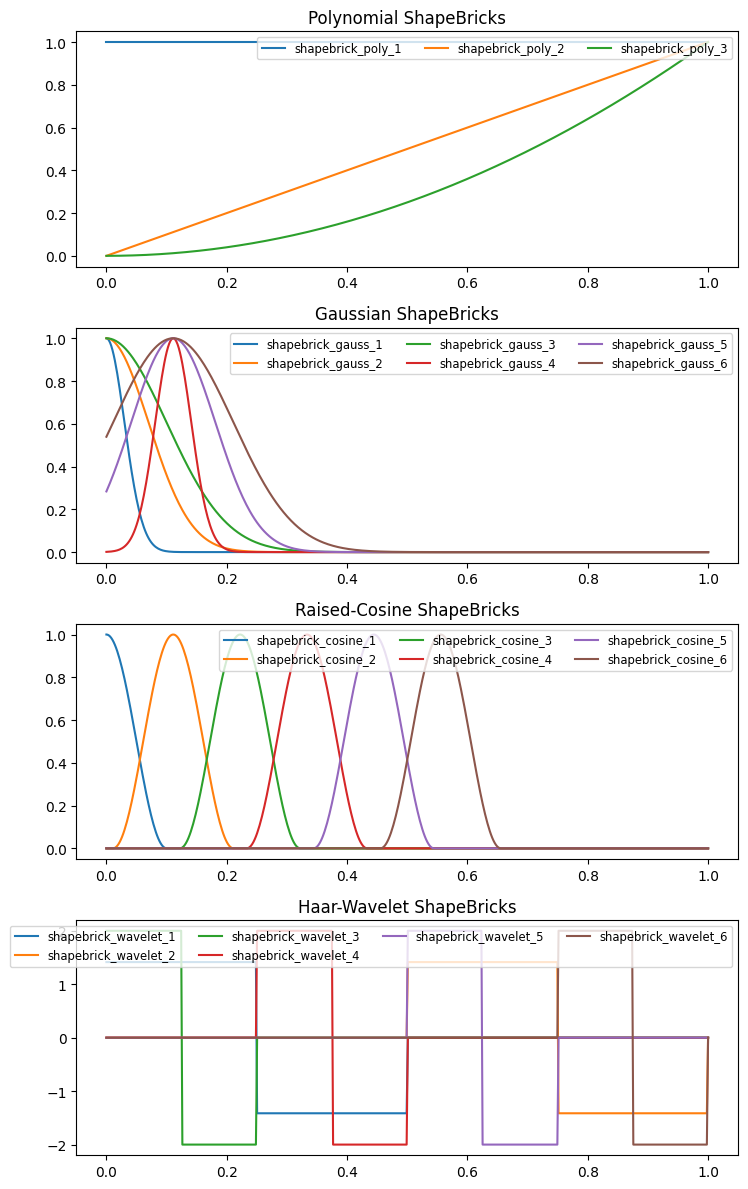

In [ ]:

# Native sampling grids
t_hf = np.linspace(0,1,500)
t_lf = np.linspace(0,1,100)

# Build and visualize ShapeBricks on HF grid
P, G, C, H = build_dictionary(t_hf)
fig, axes = plt.subplots(4,1, figsize=(8,12))
for i in range(P.shape[1]):
    axes[0].plot(t_hf, P[:,i], label=f"shapebrick_poly_{i+1}")
axes[0].set_title("Polynomial ShapeBricks")
axes[0].legend(loc='upper right', ncol=3, fontsize='small')

for i in range(min(6, G.shape[1])):
    axes[1].plot(t_hf, G[:,i], label=f"shapebrick_gauss_{i+1}")
axes[1].set_title("Gaussian ShapeBricks")
axes[1].legend(loc='upper right', ncol=3, fontsize='small')

for i in range(min(6, C.shape[1])):
    axes[2].plot(t_hf, C[:,i], label=f"shapebrick_cosine_{i+1}")
axes[2].set_title("Raised-Cosine ShapeBricks")
axes[2].legend(loc='upper right', ncol=3, fontsize='small')

for i in range(min(6, H.shape[1])):
    axes[3].plot(t_hf, H[:,i], label=f"shapebrick_wavelet_{i+1}")
axes[3].set_title("Haar-Wavelet ShapeBricks")
axes[3].legend(loc='upper right', ncol=4, fontsize='small')

plt.tight_layout()
plt.show()


Next we collect all values for the values of the Shapebricks on the two signals, i.e. low and high fidelity respectively evaluated at the two different resultutions in a single array. We also collect multiple low-fidelity samples with noise and get an ensemble of LF coefficents to make learning more robust


In [ ]:

# Assemble full dictionaries for HF and LF grids
Phi_hf = np.hstack([P, G, C, H])
P_lf, G_lf, C_lf, H_lf = build_dictionary(t_lf)
Phi_lf = np.hstack([P_lf, G_lf, C_lf, H_lf])
K = Phi_hf.shape[1]

# Generate dataset of N examples
N = 50
coeffs_hf = np.zeros((N, K))
coeffs_lf = np.zeros((N, K))
y_lf_all  = np.zeros((N, len(t_lf)))
for i in range(N):
    y_hf, y_lf = generate_pair(t_hf, t_lf)
    coeffs_hf[i] = solve_coeffs(Phi_hf, y_hf)
    coeffs_lf[i] = solve_coeffs(Phi_lf, y_lf)
    y_lf_all[i]  = y_lf

We compute the difference **deltas** between the coefficients coming from low and high fidelity - and split between train and test set

In [ ]:
# Compute delta-coefficients and split
deltas = coeffs_hf - coeffs_lf
idxs = np.arange(N)
train_idx, test_idx = train_test_split(idxs, test_size=0.3, random_state=0)
X_train, X_test = coeffs_lf[train_idx], coeffs_lf[test_idx]
d_train, d_test = deltas[train_idx], deltas[test_idx]

next cell is standard ml stuff, we scale the features and train a model on the differences

In [ ]:

# Standardize LF-coefficient features
scaler    = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

# Train Δ-model (Random Forest)
model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=3,
    n_jobs=-1,
    random_state=0
)
model.fit(X_train_s, d_train)


RandomForestRegressor(max_depth=12, min_samples_leaf=3, n_estimators=300,
                      n_jobs=-1, random_state=0)

Predict the differences between low and high fidelity and print the error on the differences

In [ ]:

# Evaluate Δ prediction
d_pred    = model.predict(X_test_s)
mae_delta = mean_absolute_error(d_test, d_pred)
print(f"Delta MAE: {mae_delta:.4f}")


Delta MAE: 0.0633


Finally reconstruct the signal

Signal reconstruction MAE: 0.0218


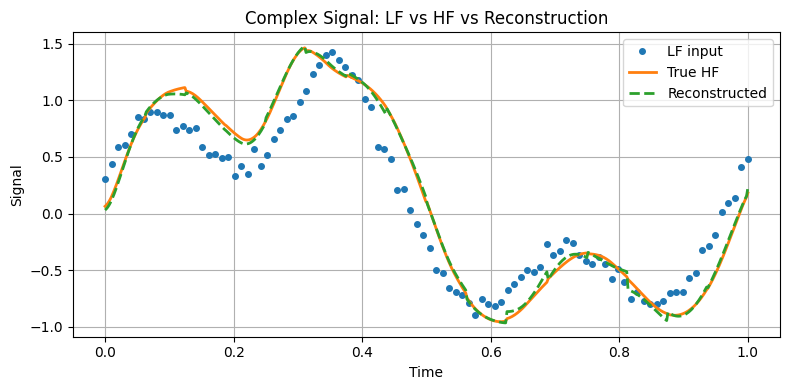

Pipeline saved to delta_pipeline_complex.joblib


In [ ]:
# Reconstruct and evaluate one example
example_idx    = test_idx[0]
a_lf           = coeffs_lf[example_idx]
a_lf_scaled    = scaler.transform(a_lf[None,:])
d_hat          = model.predict(a_lf_scaled)[0]
a_hf_hat       = a_lf + d_hat
y_hat          = Phi_hf @ a_hf_hat
y_true         = Phi_hf @ coeffs_hf[example_idx]
y_lf_example   = y_lf_all[example_idx]
mae_signal     = mean_absolute_error(y_true, y_hat)
print(f"Signal reconstruction MAE: {mae_signal:.4f}")

# Plot LF, true HF, and reconstructed HF together
plt.figure(figsize=(8,4))
plt.plot(t_lf, y_lf_example, 'o', label='LF input', markersize=4)
plt.plot(t_hf, y_true,    '-', label='True HF',       linewidth=2)
plt.plot(t_hf, y_hat,    '--', label='Reconstructed', linewidth=2)
plt.xlabel("Time"); plt.ylabel("Signal")
plt.title("Complex Signal: LF vs HF vs Reconstruction")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.show()

# Save the trained pipeline
joblib.dump({'model': model, 'scaler': scaler}, 'delta_pipeline_complex.joblib')
print("Pipeline saved to delta_pipeline_complex.joblib")